# Phase 03: data preparation

## From the biological subgraph to a spiking network we can simulate

Phase 02 delivered a directed graph of neurons and connections, each connection with a weight and a sign. This notebook turns that graph into a network that can be simulated and compared fairly. We organize the project by the phases of CRISP-DM, a standard process model for data-mining projects (Chapman et al., 2000), and this is its data-preparation phase. In the KDD process (Fayyad et al., 1996) it covers preprocessing and transformation.

Each of Sections 2 to 6 settles one modeling choice.

1. How to treat the modulatory connections.
2. How to normalize the synaptic weights.
3. How strong the lateral inhibition must be for learning to stay stable.
4. At which operating point the topologies will be compared.
5. How far a weight may grow during learning.

We make every choice with a sweep, and every sweep uses **several random seeds**. That last point is not a detail. A calibration checked on one seed can describe a lucky realization instead of a property of the network.

### Background for readers new to spiking networks

A **spiking neural network** (SNN) is a network whose neurons communicate with brief electrical events called **spikes**, as real neurons do. The number of spikes a neuron fires per second is its **firing rate**, measured in hertz (Hz). We simulate the network with Brian2 (Stimberg et al., 2019).

Each model neuron is a **leaky integrate-and-fire** (LIF) neuron. It adds up the current that reaches it and slowly leaks that charge away. When its voltage crosses a threshold it fires a spike and is reset. Our version has three **synaptic channels**, one for each kind of incoming connection (excitatory, inhibitory and modulatory). Each channel has its own decay time.

The wiring comes from phase 02. A **connection** is a directed pair of neurons. Its weight is the number of **synaptic contacts** between them, the physical sites where one neuron passes a signal to the other. Only the JO neurons of the fly's ear (Johnston's organ) that send at least one connection onward receive the sound, and they form the **input layer**. The sound itself is the stimulus of phase 04, synthetic courtship songs with five different intervals between their pulses, already converted into input spikes.

Two mechanisms let the network learn. **Spike-timing-dependent plasticity** (STDP) is a local learning rule. A connection gets stronger when the sending neuron fires just before the receiving one, and weaker when it fires just after. **Winner-take-all** (WTA) inhibition is a pool of inhibitory neurons that holds the network back when many neurons fire at once, so that a few of them specialize.

The project compares three wirings, or **topologies**. The **connectome** is the real one. The two controls are random networks with the same neurons. An **Erdős–Rényi** graph keeps only the number of connections of each sign (Erdős & Rényi, 1959). A **configuration model** also keeps how many connections enter and leave each neuron (Molloy & Reed, 1995). Each topology runs without plasticity (static weights) and with STDP + WTA, and each of these six combinations is an experimental **arm**. A **seed** is the number that fixes a random generator so that a run can be repeated exactly. Changing it changes the random wiring of the controls, the input spike trains and the starting voltages.

## 0. Environment

The cell loads the subgraph from `data/processed/` and prints its size and the number of connections of each polarity.

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from snnlib import audio as A, calibration as CAL, evaluation as E, graph, network as NET, FIGURES

OUT_DIR = Path('outputs'); OUT_DIR.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':150,'savefig.bbox':'tight',
                     'axes.titleweight':'bold','font.size':10})
BLUE, RED, GREEN, PURPLE = '#2E86AB','#C73E1D','#3CAEA3','#7B68A6'
SEEDS = [0,1,2,3,4]

C = graph.load()
print(f'Subgraph: {C.N} neurons, {len(C.pre):,} connections '
      f'({int(C.raw_weight.sum()):,} synaptic contacts), '
      f'{C.N_input} neurons in the input layer')
print('Polarities:', {k:int(v.sum()) for k,v in C.mask.items()})

Subgraph: 1239 neurons, 20,059 connections (338,013 synaptic contacts), 123 neurons in the input layer
Polarities: {'Excitatory': 8512, 'Inhibitory': 11437, 'Modulatory': 110}


## 1. The neuron model

Each neuron is a leaky integrate-and-fire neuron with **three separate synaptic channels**, one per polarity, each with its own time constant.

$$\tau_m \frac{dv}{dt} = -(v - V_{rest}) + R_m (I_{exc} + I_{inh} + I_{mod})$$

Here $v$ is the membrane voltage and $V_{rest}$ the resting potential it relaxes to. The membrane time constant $\tau_m$ sets how fast the neuron forgets its input, $R_m$ is the membrane resistance, and $I_{exc}$, $I_{inh}$ and $I_{mod}$ are the currents of the three channels. When $v$ crosses the threshold $V_{thresh}$, the neuron fires, drops to $V_{reset}$ and stays silent for a refractory period $\tau_{ref}$.

The synaptic time constants are modeling choices inspired by typical mammalian values. The excitatory channel decays in 5 ms, close to the decay of AMPA-receptor currents, and the inhibitory one in 10 ms, within the GABA-A range. The modulatory channel decays in 50 ms, which makes it deliberately slower. Real metabotropic and neuromodulatory effects are slower still, so this channel is a simplified stand-in, not a model of neuromodulation (Gerstner et al., 2014).

> **Read the table below with care.** It prints the **default** values of `snnlib/network.py`, not the ones this work uses. This notebook recalibrates three of them, and the calibrated values are stored in `outputs/operating_point.json` or set in the code. `wta_inh` goes from 0.1 to **0.6 nA** (Section 4), `w_input` is set **per arm** between 5.1 and 17.6 nA (Section 5), and `wmax_factor` gives way to the largest initial weight (Section 6). The experiments of phase 04 always read the JSON file.

**Where the parameters come from.** The resting, reset and threshold potentials (−65, −65 and −52 mV) follow the published code of Diehl and Cook (2015). The membrane parameters lie in the ranges commonly used for LIF models (τm = 10 ms, Gerstner et al., 2014; Rm = 10 MΩ, Dayan & Abbott, 2001), and the refractory period is 2 ms. None of these values was measured in *Drosophila* JO or AMMC neurons. The current amplitudes (`alpha_*`, `w_input`) come from no publication either. We calibrate them in this notebook, and we say so instead of attributing them to sources that use other values.

In [2]:
print('Model parameters (snnlib/network.py):')
for k,v in NET.P.items():
    print(f'  {k:14s} {v}')

Model parameters (snnlib/network.py):
  V_rest         -65.0
  V_reset        -65.0
  V_thresh       -52.0
  tau_m          10.0
  tau_ref        2.0
  R_m            10.0
  tau_exc        5.0
  tau_inh        10.0
  tau_mod        50.0
  alpha_exc      1.5
  alpha_inh      0.75
  alpha_mod      1.0
  w_input        3.0
  stdp_Aplus     0.05
  stdp_Aminus    0.0525
  stdp_tau       20.0
  wta_n          50
  wta_exc        1.0
  wta_inh        0.1
  wta_p          0.25
  wmax_factor    None


How to read the keys. `V_rest`, `V_reset` and `V_thresh` are the three potentials (mV). `tau_m` and `tau_ref` are the membrane time constant and the refractory period (ms), and `R_m` is the membrane resistance (MΩ). `tau_exc`, `tau_inh` and `tau_mod` are the decay times of the three channels (ms). `alpha_exc`, `alpha_inh` and `alpha_mod` set the current (nA) that a spike injects through a connection of normalized weight 1 into each channel. `w_input` is the current that each input spike adds to the JO neuron that receives it.

The `stdp_*` keys define the learning rule, described in the summary at the end. The four `wta_*` keys describe the winner-take-all layer, namely its number of interneurons, the excitation each interneuron receives from the network, the inhibition it sends back and the fraction of the network it reaches. `wmax_factor` sets the weight ceiling (Section 6).

## 2. Treatment of the modulatory connections

Serotonin, dopamine and octopamine are **neuromodulators**. A neuron that releases them does not simply excite or inhibit its target with a fast pulse of current. It changes, slowly, how strongly the target responds. Their connections pose a modeling problem, because they fit neither the excitatory nor the inhibitory channel.

Phase 02 assigned one neurotransmitter to each neuron, following the neuron-level predictions of Eckstein et al. (2024). With that assignment only 110 connections are modulatory, 0.5 % of the total. The earlier assignment, made connection by connection, had produced many more of them, and most were classifier noise.

With so few of them, two treatments are reasonable and we compare both. We either keep them in their own slow channel or switch them off. An earlier version also tried a third variant, folding them into weak excitatory connections. We dropped it, because with 110 connections it cannot be told apart from switching them off.

**A same-network comparison.** Deleting the modulatory connections would leave some neurons with no connection at all and change the size of the network, so the comparison would mix two effects. To avoid that, the "no modulators" condition keeps every neuron and sets the gain of those connections to zero. The network is identical, and only the modulatory channel changes.

The function below runs the static connectome (no plasticity, no WTA, default input gain) on two presentations of each song per seed. It reports the mean firing rate and two measures of how the response is spread. The **coverage** is the percentage of neurons that fire at least once during a presentation. The **selectivity** is the normalized Treves–Rolls sparseness, which goes from 0, when every neuron responds equally, to 1, when a single neuron responds (Vinje & Gallant, 2000).

In [3]:
def sweep_conditions(conditions, seeds=SEEDS, n=2):
    rows=[]
    for name, params in conditions.items():
        rates, coverages, selectivities = [], [], []
        for s in seeds:
            stim = E.Stimuli(); mapping = C.channel_map(A.N_CHANNELS)
            I,T,V,y,dur = E.build_sequence(stim, mapping, n, s*100, s)
            r = NET.simulate(C, I, T, dur, seed=s, topology_seed=s, params=params)
            M = NET.counts_per_window(r['t'], r['i'], V, C.N)
            rates.append(M.sum()/C.N/(len(V)*A.DURATION))
            coverages.append(100*np.mean((M>0).sum(axis=1))/C.N)
            selectivities.append(np.mean([E.sparseness(x) for x in M]))
        rows.append(dict(condition=name,
                          rate=np.mean(rates), rate_sd=np.std(rates),
                          coverage=np.mean(coverages), selectivity=np.mean(selectivities)))
    return pd.DataFrame(rows).set_index('condition')

modulator_table = sweep_conditions({
    'own slow channel (τ = 50 ms)':  dict(alpha_mod=1.0),
    'no modulators (gain 0)': dict(alpha_mod=0.0),
})
print('Same-network comparison: the same 1,239 nodes in both conditions;')
print('only the gain of the modulatory channel changes.\n')
modulator_table.round(3)

WARNING    Removing unsupported flag '-march=native' from compiler flags. [brian2.codegen.cpp_prefs]


Same-network comparison: the same 1,239 nodes in both conditions;
only the gain of the modulatory channel changes.



,rate,rate_sd,coverage,selectivity
condition,,,,
own slow channel (τ = 50 ms),2.322,0.044,18.960,0.889
no modulators (gain 0),2.288,0.050,18.618,0.888


Switching the modulatory channel off lowers the mean rate from 2.322 to 2.288 Hz. Coverage and selectivity barely move. The rates are low because these runs use the default input gain of 3.0 nA, before the operating point is matched in Section 5. The next cell asks how far the gain can be pushed before it starts to matter.

(The warning printed by Brian2 about the `-march=native` compiler flag is harmless. It only says that the flag is not supported on this processor.)

                   rate  rate_sd  coverage  selectivity
condition                                              
alpha_mod = 0.0   2.288    0.050    18.618        0.888
alpha_mod = 0.5   2.299    0.050    18.818        0.887
alpha_mod = 1.0   2.322    0.044    18.960        0.889
alpha_mod = 2.0   2.477    0.065    19.004        0.905
alpha_mod = 4.0  21.176    0.389    16.772        0.934

Between alpha_mod = 0 and alpha_mod = 2 the rate moves only 0.189 Hz (8.1 % of the mean).
At alpha_mod = 4, by contrast, the network jumps to 21.2 Hz
with a spread across seeds of 0.4 Hz:
the slow depolarizing floor pushes the network into an unstable regime.


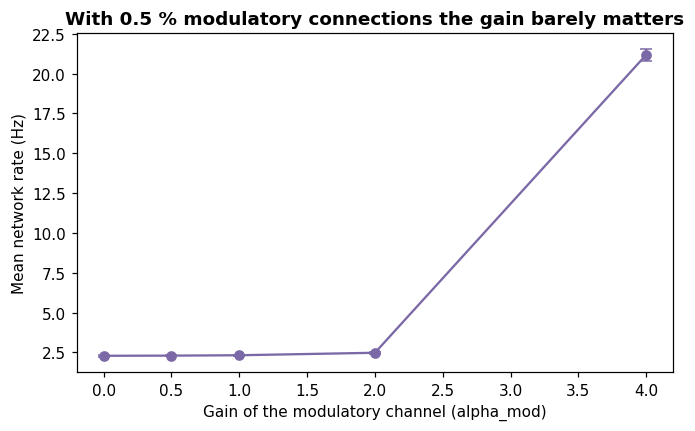

In [4]:
# Sweep of the modulatory-channel gain
gain_table = sweep_conditions({f'alpha_mod = {a}': dict(alpha_mod=a) for a in [0.0, 0.5, 1.0, 2.0, 4.0]})
print(gain_table.round(3).to_string())
print()
stable_part = gain_table.loc[['alpha_mod = 0.0','alpha_mod = 0.5','alpha_mod = 1.0','alpha_mod = 2.0']]
print(f'Between alpha_mod = 0 and alpha_mod = 2 the rate moves only '
      f'{stable_part.rate.max()-stable_part.rate.min():.3f} Hz '
      f'({100*(stable_part.rate.max()-stable_part.rate.min())/stable_part.rate.mean():.1f} % of the mean).')
print(f'At alpha_mod = 4, by contrast, the network jumps to {gain_table.loc["alpha_mod = 4.0"].rate:.1f} Hz')
print(f'with a spread across seeds of {gain_table.loc["alpha_mod = 4.0"].rate_sd:.1f} Hz:')
print('the slow depolarizing floor pushes the network into an unstable regime.')

fig, ax = plt.subplots(figsize=(7,4))
x = [0.0,0.5,1.0,2.0,4.0]
ax.errorbar(x, gain_table.rate, yerr=gain_table.rate_sd, marker='o', color=PURPLE, capsize=4)
ax.set_xlabel('Gain of the modulatory channel (alpha_mod)')
ax.set_ylabel('Mean network rate (Hz)')
ax.set_title('With 0.5 % modulatory connections the gain barely matters')
fig.savefig(FIGURES/'03-modulator-gain-sweep.png'); plt.show()

**Decision: `alpha_mod = 1.0`.** The sweep shows two regimes. Between gain 0 and 2 the dynamics hardly care. Turning the knob moves the mean rate by 0.189 Hz, 8.1 % of the mean, and leaves coverage and selectivity where they were. Past that point the slow channel stops acting as a gain control and starts to drive the network. At `alpha_mod = 4` the rate **rises 8.5-fold** (2.48 → 21.18 Hz) while **coverage falls** (19.0 → 16.8 %) and selectivity rises (0.905 → 0.934). There are many more spikes, spread over fewer neurons. A subpopulation runs away instead of the whole network turning up its gain.

The spread across seeds is **not** the warning sign here. At gain 4 it is 0.389 Hz, which over 21.2 Hz is a coefficient of variation of 1.8 %, the smallest in the table. The five realizations agree that the network runs away. What gives the change of regime away is the jump in rate together with the drop in coverage.

So we keep the unit value. It sits inside the flat zone and keeps neuromodulation in its own slow channel instead of deleting it. The important conclusion is that **with 0.5 % modulatory connections the choice is no longer critical**, as long as the gain stays out of the unstable regime.

This corrects an earlier conclusion. When the neurotransmitter was assigned connection by connection, modulatory labels were several times more common, and their treatment seemed to change the dynamics markedly. With one transmitter per neuron most of those labels turn out to be classifier noise, and the effect fades away.

## 3. Normalization of the synaptic weights

The raw weight of a connection is its number of synaptic contacts, with a median of 10 and a maximum of 347. **Weight normalization** puts the weights on a common scale, so that the current amplitudes calibrated in this notebook apply to a weight of about 1. The scheme also decides how much of the long tail survives. We compare three schemes.

| Scheme | Transformation | What it keeps |
|---|---|---|
| mean | `w / mean(w)` | the full dynamic range, tail included |
| median | `w / median(w)` | the same, with more gain per typical contact |
| logarithmic | `log(1+w) / mean(log(1+w))` | compresses the long tail |

We leave out a fourth scheme built on the constant weight per synapse of Shiu et al. (2024). In this subgraph the median is exactly 10, so dividing by the median and rescaling the amplitudes by 10 give the same model. Presenting the two as schemes that "agree" would report an algebraic identity as if it were a finding.

The next cell prints the statistics of each scheme and draws the three distributions on a common grid of bins. The plot stops at a normalized weight of 8, while the tails of the mean and median schemes go on to 20.59 and 34.70.

Statistics of each normalization:
  mean         mean= 1.000  median= 0.593  max=   20.59  p99=  6.231
  median       mean= 1.685  median= 1.000  max=   34.70  p99= 10.500
  logarithmic  mean= 1.000  median= 0.933  max=    2.28  p99=  1.815

Check: median of the raw weight = 10.0. That is why
normalizing by the median is the same as normalizing by the mean and rescaling
the amplitudes by 1.685.


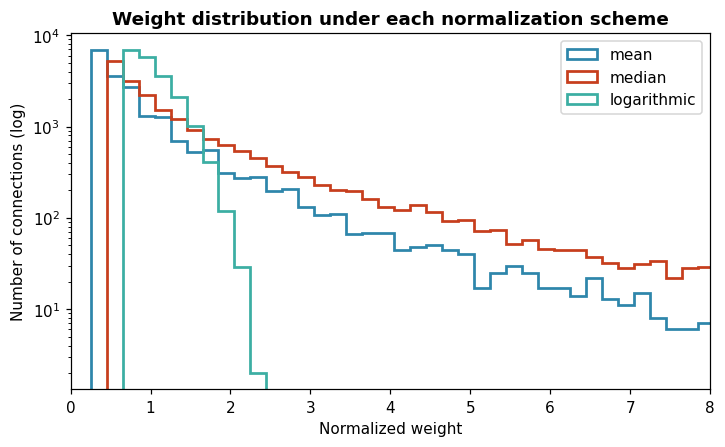

In [5]:
raw_w = C.raw_weight
schemes = {
    'mean':        raw_w/raw_w.mean(),
    'median':      raw_w/np.median(raw_w),
    'logarithmic':  np.log1p(raw_w)/np.log1p(raw_w).mean(),
}
print('Statistics of each normalization:')
for k,v in schemes.items():
    print(f'  {k:12s} mean={v.mean():6.3f}  median={np.median(v):6.3f}  '
          f'max={v.max():8.2f}  p99={np.percentile(v,99):7.3f}')
print()
print(f'Check: median of the raw weight = {np.median(raw_w):.1f}. That is why')
print('normalizing by the median is the same as normalizing by the mean and rescaling')
print(f'the amplitudes by {raw_w.mean()/np.median(raw_w):.3f}.')

fig, ax = plt.subplots(figsize=(7.5,4.2))
for (k,v),c in zip(schemes.items(), [BLUE,RED,GREEN]):
    ax.hist(v, bins=np.arange(0.05, 8.1, 0.2), histtype='step', lw=1.8, color=c, label=k)
ax.set_yscale('log'); ax.set_xlim(0,8)
ax.set_xlabel('Normalized weight'); ax.set_ylabel('Number of connections (log)')
ax.legend(); ax.set_title('Weight distribution under each normalization scheme')
fig.savefig(FIGURES/'03-weight-normalization.png'); plt.show()

The median scheme has the same shape as the mean scheme, shifted to the right by a factor of 1.685, because the mean weight is 1.685 times the median. The logarithmic scheme squeezes every weight below 2.28.

The next cell measures how stable learning is under each scheme. It runs the connectome with STDP + WTA (input gain 3.0 nA, `wta_inh` = 0.6 nA) on three presentations of each song per seed and reports three numbers. The first is the firing rate. The second, the mean weight change **|Δw|**, is the average absolute change of the excitatory weights between the start and the end of the run. The third is the **drift**, the spread of the mean weight over the last fifth of the run. A small drift means that learning has settled, and a large one means that the weights are still moving.

In [6]:
# Learning stability under each scheme, with several seeds
def norm_stability(name, w_norm, seeds=SEEDS):
    orig = C.w.copy(); C.w = w_norm
    try:
        r = CAL.stdp_stability(C, 'connectome', w_input=3.0, wta_inh=0.6, seeds=seeds)
    finally:
        C.w = orig
    return dict(scheme=name, **r)

stab = pd.DataFrame([norm_stability(k,v) for k,v in schemes.items()]).set_index('scheme')
stab.round(4)

,rate,rate_sd,dw,drift
scheme,,,,
mean,2.5680,0.1230,0.1746,0.0070
median,3.2041,0.1631,0.2615,0.0120
logarithmic,2.3420,0.1199,0.1042,0.0036


**Decision.** We adopt the normalization by the **mean**. It keeps the dynamic range of the long tail, which is real information in the connectome (some connections have 347 contacts, others 5), and its drift under plasticity stays low (0.0070, against 0.0120 with the median).

The logarithmic scheme is even more stable, with a drift of 0.0036, but it **flattens the weight hierarchy**. The ratio between the strongest connection and the median goes from **34.7×** with the mean scheme to **2.4×** with the logarithmic one (a maximum of 2.28 against a median of 0.933). The weights do not become equal. Still, the contrast between a connection of 347 contacts and one of 10 shrinks fourteenfold, and that contrast is exactly the biological property this work sets out to test.

## 4. Lateral inhibition: calibrating the WTA

STDP makes the connections onto one neuron compete with each other (Song et al., 2000), but on its own it does not make different neurons learn different inputs. Without competition between neurons, many of them end up strengthening the same connections. **Winner-take-all** inhibition adds that competition (Diehl & Cook, 2015; Masquelier et al., 2009). A pool of 50 inhibitory **interneurons**, neurons that connect other neurons inside a circuit, receives excitation from the whole network and sends inhibition back. When some neurons fire strongly, the others are held down.

We use the **sparse** variant, in which each interneuron inhibits only a random fraction of the network (`wta_p = 0.25`) and not all of it. The dense variant silenced the network. In mammalian cortex, inhibitory interneurons act mostly locally (Isaacson & Scanziani, 2011), and our sparse layer is a computational simplification inspired by that. It is not a model of the inhibitory circuitry of the fly.

The knob left to set is the **strength** of that inhibition, `wta_inh`. Too low, and plasticity runs away. Too high, and the network goes quiet. We sweep it on **all three topologies**, because `wta_inh` is shared by every plastic arm. A value that stabilizes the connectome but not the controls would leave the comparison lopsided. Each point is the mean over five seeds, with the default input gain of 3.0 nA. The sweep takes a few minutes and writes `outputs/wta_sweep.csv`.

In [7]:
t0=time.time()
rows=[]
for topo in ['connectome','er','configuration']:
    for wi in [0.1,0.2,0.3,0.6,1.0]:
        r = CAL.stdp_stability(C, topo, w_input=3.0, wta_inh=wi, seeds=SEEDS)
        rows.append(dict(topology=topo, wta_inh=wi, **r))
        print(f'  {topo:13s} wta_inh={wi:4.2f}  rate={r["rate"]:6.2f}±{r["rate_sd"]:4.2f} Hz  '
              f'|dw|={r["dw"]:.4f}  drift={r["drift"]:.5f}', flush=True)
wta_sweep = pd.DataFrame(rows)
wta_sweep.to_csv(OUT_DIR/'wta_sweep.csv', index=False)
print(f'({time.time()-t0:.0f}s)')


  connectome    wta_inh=0.10  rate=  4.10±0.40 Hz  |dw|=0.2785  drift=0.01114


  connectome    wta_inh=0.20  rate=  3.36±0.25 Hz  |dw|=0.2260  drift=0.00626


  connectome    wta_inh=0.30  rate=  3.03±0.12 Hz  |dw|=0.2063  drift=0.00693


  connectome    wta_inh=0.60  rate=  2.57±0.12 Hz  |dw|=0.1746  drift=0.00696


  connectome    wta_inh=1.00  rate=  2.31±0.11 Hz  |dw|=0.1549  drift=0.00681


...

  configuration wta_inh=0.20  rate= 11.05±3.19 Hz  |dw|=0.3746  drift=0.01315


  configuration wta_inh=0.30  rate=  8.62±1.35 Hz  |dw|=0.4090  drift=0.02909


  configuration wta_inh=0.60  rate=  4.43±0.71 Hz  |dw|=0.2922  drift=0.01528


  configuration wta_inh=1.00  rate=  3.40±0.25 Hz  |dw|=0.2378  drift=0.01087


(197s)


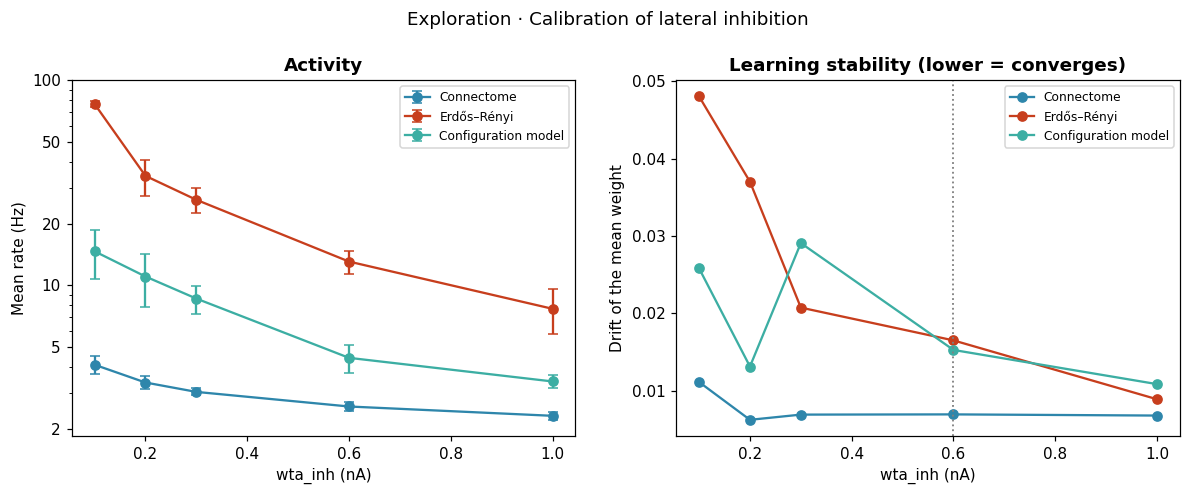

Value of minimum drift per topology:
     topology  wta_inh     rate    drift
configuration      1.0 3.401453 0.010870
   connectome      0.2 3.361385 0.006260
           er      1.0 7.688889 0.008916


In [8]:
fig, ax = plt.subplots(1,2, figsize=(13,4.2))
for topo,c,lab in [('connectome',BLUE,'Connectome'),('er',RED,'Erdős–Rényi'),
                   ('configuration',GREEN,'Configuration model')]:
    d = wta_sweep[wta_sweep.topology==topo]
    ax[0].errorbar(d.wta_inh, d.rate, yerr=d.rate_sd, marker='o', color=c, capsize=3, label=lab)
    ax[1].plot(d.wta_inh, d.drift, 'o-', color=c, label=lab)
ax[0].set_yscale('log'); ax[0].set_xlabel('wta_inh (nA)'); ax[0].set_ylabel('Mean rate (Hz)')
ax[0].set_yticks([2, 5, 10, 20, 50, 100], ['2', '5', '10', '20', '50', '100'])
ax[0].set_title('Activity'); ax[0].legend(fontsize=8)
ax[1].set_xlabel('wta_inh (nA)'); ax[1].set_ylabel('Drift of the mean weight')
ax[1].set_title('Learning stability (lower = converges)'); ax[1].legend(fontsize=8)
ax[1].axvline(0.6, color='gray', ls=':', lw=1.2)
fig.suptitle('Exploration · Calibration of lateral inhibition', y=1.03)
fig.savefig(FIGURES/'03-wta-inhibition-calibration.png'); plt.show()

best = wta_sweep.loc[wta_sweep.groupby('topology').drift.idxmin()]
print('Value of minimum drift per topology:')
print(best[['topology','wta_inh','rate','drift']].to_string(index=False))


**Decision: `wta_inh = 0.6 nA`.** It is the value that keeps runaway activity in check on the three topologies at once. It is not the minimum-drift value of any of them taken alone, which would be 0.2 for the connectome and 1.0 for the Erdős–Rényi network and the configuration model (the table above lists them in alphabetical order of the topology name). It is a compromise between stability and activity. Below it the controls fire far above the connectome and drift more. At 1.0 nA the drift is slightly lower still in all three topologies, but the connectome falls to 2.31 Hz and its weights move less (|Δw| of 0.1549 against 0.1746).

With the low value used before (0.1 nA), the Erdős–Rényi network fires at 76.60 Hz, 18.7 times the rate of the connectome, and its weight drift is 4.3 times larger (0.04803 against 0.01114). A comparison made there would not measure topology. It would measure which network loses stability first.

**At 0.6 nA the configuration model falls between the two extremes in rate, drift and |Δw|.** That is what one would expect from a topology that keeps the degrees of the connectome but not its fine wiring. At `wta_inh = 0.6` its rate is 4.43 Hz (between 2.57 and 13.07), its drift 0.01528 (between 0.00696 and 0.01652) and its |Δw| 0.2922 (between 0.1746 and 0.3056). The shared value keeps it in range without any special treatment.

One caveat is worth recording. At 0.6 nA its **relative spread across seeds is the largest of the three**, 15.9 % against 13.0 % for Erdős–Rényi and 4.8 % for the connectome. This fits with it being the arm with the largest accuracy variance in phase 04 (0.768 ± 0.148 with fifteen seeds), and it is worth keeping in mind when reading that contrast.

**A note on method.** Every number in this section is a mean over five seeds. That is deliberate. An earlier calibration of this same mechanism was checked on a single seed, and its values did not hold when the seed changed.

## 5. A matched operating point

This is the decision that makes the comparison of phase 04 meaningful.

Fed with the same input gain, the three topologies fire at very different rates. They have the same number of connections of each polarity, so the difference comes from where those connections are placed. Compared that way, a network that simply fires more would hand more spikes to the classifier that reads it out, and it would look like a better classifier without being one.

So we fix a common **operating point**, the same mean firing rate in every arm, measured from the untrained weights before the experiment. In the arms with plasticity, plasticity is already active during that short calibration run. Then we tune the input gain `w_input` of each arm until it reaches that rate. After that, a difference in performance can be put down to the structure of the network and not to how excitable it is.

**How the tuning works.** It is a **bisection**. The mean rate grows steadily with the input gain, so we start from an interval of gains, 0.1 to 40 nA, with one end below the target rate and the other above it. At each step we simulate the midpoint and keep the half of the interval that still contains the target. We stop when the rate is within 5 % of the target, or after 18 steps. Each evaluation averages five seeds, so the gain does not depend on one particular realization. The script `calibrate.py` runs this search for the six arms and stores the result in `outputs/operating_point.json`. This notebook only reads that file.

We choose **10 Hz**. It is a sparse but active regime that gives STDP enough pairs of spikes, and all six arms can reach it. It is our own choice, not a measured value. No firing rates have been published for these neurons, and several of the neurons that receive input from the ear respond to sound with graded potentials instead of spikes (Tootoonian et al., 2012).

> We dropped an earlier criterion, a minimum "propagation ratio" (the activity of the second-order neurons relative to that of the input layer). It had been set with uniform random input and no classification task. With real stimuli it could only be met by raising the modulatory gain until the response no longer depended on the stimulus. A calibration criterion that makes the task worse is not a good criterion.

In [9]:
op = json.loads((OUT_DIR/'operating_point.json').read_text())
tab = pd.DataFrame(op['arms']).T
tab['rate'] = tab.rate.astype(float).round(2)
tab['rate_sd'] = tab.rate_sd.astype(float).round(2)
tab['w_input'] = tab.w_input.astype(float).round(3)
print(f'Target: {op["target_hz"]} Hz | wta_inh = {op["wta_inh"]} | '
      f'seeds: {op["seeds"]}')
tab[['topology','stdp','w_input','rate','rate_sd','converged']]

Target: 10.0 Hz | wta_inh = 0.6 | seeds: [0, 1, 2, 3, 4]


,topology,stdp,w_input,rate,rate_sd,converged
connectome_static,connectome,False,10.075,10.41,0.46,True
connectome_stdp,connectome,True,17.556,10.06,0.22,True
er_static,er,False,5.088,9.83,1.58,True
er_stdp,er,True,15.062,10.16,0.69,True
configuration_static,configuration,False,6.334,10.14,0.91,True
configuration_stdp,configuration,True,15.062,10.16,0.69,True


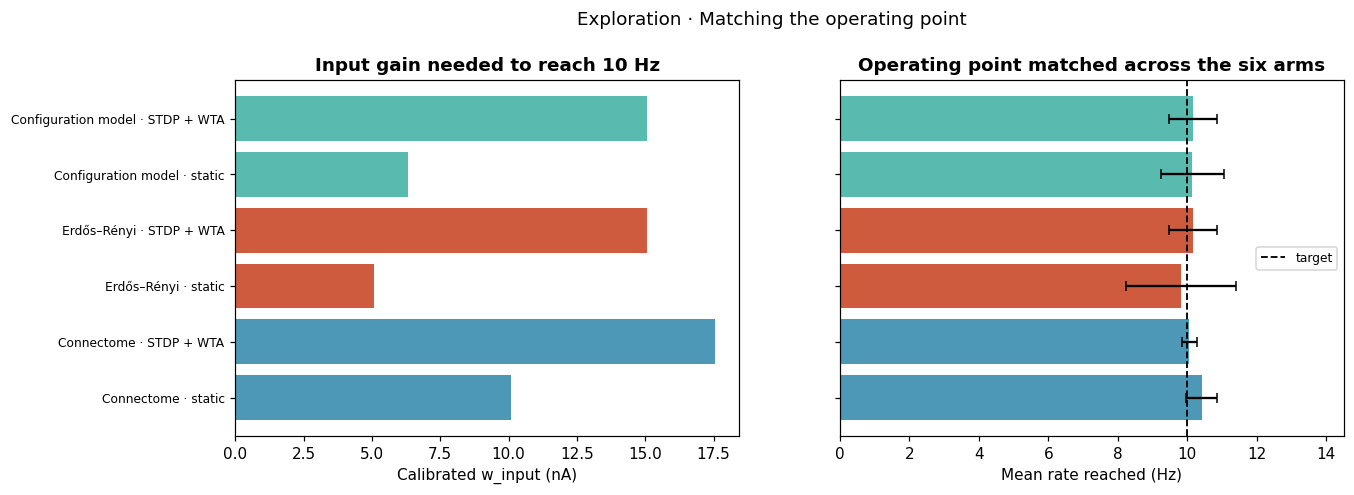

The connectome needs almost twice the input gain of the
random network (10.08 against 5.09 nA) to reach the same rate: its
wiring dissipates more of the excitation.
That is a result in itself, and it is exactly the factor that would have
confounded the comparison if the rates had not been matched.


In [10]:
fig, ax = plt.subplots(1,2, figsize=(13,4.2))
names = list(op['arms']); cols=[BLUE if 'connectome' in n else (RED if n.startswith('er') else GREEN) for n in names]
w = [op['arms'][n]['w_input'] for n in names]
t = [op['arms'][n]['rate'] for n in names]
sd = [op['arms'][n]['rate_sd'] for n in names]
ARM_LABEL = {'connectome':'Connectome','er':'Erdős–Rényi','configuration':'Configuration model'}
labels = [f"{ARM_LABEL[op['arms'][n]['topology']]} · {'STDP + WTA' if op['arms'][n]['stdp'] else 'static'}"
          for n in names]
ax[0].barh(range(len(names)), w, color=cols, alpha=.85)
ax[0].set_yticks(range(len(names))); ax[0].set_yticklabels(labels, fontsize=8)
ax[0].set_xlabel('Calibrated w_input (nA)')
ax[0].set_title('Input gain needed to reach 10 Hz')
ax[1].barh(range(len(names)), t, xerr=sd, color=cols, alpha=.85, capsize=3)
ax[1].axvline(op['target_hz'], color='k', ls='--', lw=1.2, label='target')
ax[1].set_yticks(range(len(names))); ax[1].set_yticklabels([])
ax[1].set_xlim(0, 14.5)
ax[1].set_xlabel('Mean rate reached (Hz)'); ax[1].legend(fontsize=8, loc='center right')
ax[1].set_title('Operating point matched across the six arms')
fig.suptitle('Exploration · Matching the operating point', y=1.03)
fig.savefig(FIGURES/'03-operating-point-calibration.png'); plt.show()

print('The connectome needs almost twice the input gain of the')
print('random network (10.08 against 5.09 nA) to reach the same rate: its')
print('wiring dissipates more of the excitation.')
print('That is a result in itself, and it is exactly the factor that would have')
print('confounded the comparison if the rates had not been matched.')


All six arms land close to the target, between 9.83 and 10.41 Hz, and the bisection converged in every case. The input gains, on the other hand, differ by more than a factor of three, from 5.088 nA (Erdős–Rényi, static) to 17.556 nA (connectome, STDP + WTA). The plastic arms need more gain than the static ones because they run with the WTA layer switched on and with plasticity changing their weights during the calibration run.

The connectome needs about twice the input gain of the random network to reach the same rate (10.075 against 5.088 nA in the static arms). Its wiring dissipates much more of the excitation. The three wirings have the same number of inhibitory connections (an E/I ratio of 0.7443 in all of them), so the difference has to come from where the connections are placed. The modular organization of the connectome, which keeps activity confined, is a plausible cause. That factor of two is exactly the confound that would have contaminated any comparison made without matching.

The random network is also less stable across seeds in the static condition (± 1.58 Hz against ± 0.46 Hz for the connectome). Its behavior depends more on the particular draw of its wiring.

The calibration uses the courtship-song stimulus of phase 04, not tones. The operating point depends on the stimulus, so calibrating it with a different one would be inconsistent.

## 6. Weight ceiling under plasticity

The weight ceiling `wmax` caps how much a connection can grow during learning. STDP clips any weight that would go above it, as in Song et al. (2000). The earlier criterion, four times the mean weight, cut part of the long tail **before** the network had learned anything, and that truncation got mixed up with the effect of plasticity. The next cell measures what the earlier criterion clipped.

In [11]:
# Weight ceiling: what the earlier criterion clipped (wmax = 4 × the mean)
we = C.w[C.mask['Excitatory']]
old_cap = 4 * we.mean()
clipped = we > old_cap
print(f'Excitatory connections: {len(we):,}')
print(f'  earlier wmax (4 x mean) = {old_cap:.3f}')
print(f'  clipped before learning: {int(clipped.sum())} ({100*clipped.mean():.2f} %)')
print(f'  share of the weight mass they carried: {100*we[clipped].sum()/we.sum():.1f} %')
print(f'  new wmax (largest initial weight) = {we.max():.3f}  ->  clipped 0')


Excitatory connections: 8,512
  earlier wmax (4 x mean) = 3.863
  clipped before learning: 230 (2.70 %)
  share of the weight mass they carried: 16.7 %
  new wmax (largest initial weight) = 15.607  ->  clipped 0


**Decision: `wmax` = largest initial excitatory weight.** With the earlier criterion, 230 excitatory connections (2.70 %), which carried 16.7 % of the excitatory weight mass, were clipped from the start. With the new one, none is. The parameter `wmax_factor` can reproduce the earlier criterion, and phase 04 runs it as a control, because a higher ceiling has a cost of its own that is measured there.

## 7. Summary of the phase

| Decision | Value | How it was made |
|---|---|---|
| Neuron model | three-channel LIF (τ = 5 / 10 / 50 ms) | one channel per polarity of the connectome |
| Modulatory connections | own slow channel, `alpha_mod = 1.0` | gain sweep; with 0.5 % of the connections the effect is marginal |
| Normalization | by the mean | keeps the dynamic range; acceptable weight drift |
| Lateral inhibition | sparse, `wta_p = 0.25`, `wta_inh = 0.6 nA` | sweep on the three topologies, five seeds |
| Operating point | 10 Hz mean rate | bisection on `w_input` per arm, five seeds |
| STDP | `stdp_Aplus` 0.05, `stdp_Aminus` 0.0525, τ = 20 ms | form of Song et al. (2000); `wmax` = largest initial weight |

The STDP rule is additive and pair-based. The potentiation and depression windows share a time constant of 20 ms, and the depression step is 1.05 times the potentiation step, as in Song et al. (2000). Depression therefore slightly outweighs potentiation, which Song et al. showed is needed for stable, competitive learning. Our potentiation step (0.05, in units of the mean weight) is our own choice for the short training used here. Song et al. express theirs as a fraction of the maximum weight, so the two values are not on the same scale.

On `wmax`: it is the largest initial excitatory weight, so no connection is clipped before learning starts. With the earlier value (four times the mean), 2.70 % of the excitatory connections, carrying 16.7 % of the weight mass, were clipped at their first update, and that truncation got mixed up with the effect of plasticity.

The calibrated input gains and the inhibition strength are stored in `outputs/operating_point.json`, which phase 04 reads directly. The other choices are the defaults of `snnlib/network.py` and `snnlib/graph.py`. No modeling notebook writes a parameter by hand.

One limitation applies to Sections 2 to 4. Their sweeps ran with the default input gain of 3.0 nA, where the connectome fires far below the operating point used later, and we did not repeat them at the calibrated gains. The [results of this phase](results.md) and its [research log](research-log.md) discuss these choices in more detail.

## References

- Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS Inc. https://web.archive.org/web/20060207174803/http://www.crisp-dm.org/CRISPWP-0800.pdf
- Dayan, P., & Abbott, L. F. (2001). *Theoretical neuroscience: Computational and mathematical modeling of neural systems*. MIT Press. https://mitpress.mit.edu/9780262041997/theoretical-neuroscience/
- Diehl, P. U., & Cook, M. (2015). Unsupervised learning of digit recognition using spike-timing-dependent plasticity. *Frontiers in Computational Neuroscience, 9*, Article 99. https://doi.org/10.3389/fncom.2015.00099
- Eckstein, N., Bates, A. S., Champion, A., Du, M., Yin, Y., Schlegel, P., Lu, A. K.-Y., Rymer, T., Finley-May, S., Paterson, T., Parekh, R., Dorkenwald, S., Matsliah, A., Yu, S.-C., McKellar, C., Sterling, A., Eichler, K., Costa, M., Seung, S., . . . Funke, J. (2024). Neurotransmitter classification from electron microscopy images at synaptic sites in *Drosophila melanogaster*. *Cell, 187*(10), 2574–2594.e23. https://doi.org/10.1016/j.cell.2024.03.016
- Erdős, P., & Rényi, A. (1959). On random graphs I. *Publicationes Mathematicae Debrecen, 6*(3–4), 290–297. https://doi.org/10.5486/PMD.1959.6.3-4.12
- Fayyad, U., Piatetsky-Shapiro, G., & Smyth, P. (1996). From data mining to knowledge discovery in databases. *AI Magazine, 17*(3), 37–54. https://doi.org/10.1609/aimag.v17i3.1230
- Gerstner, W., Kistler, W. M., Naud, R., & Paninski, L. (2014). *Neuronal dynamics: From single neurons to networks and models of cognition*. Cambridge University Press. https://doi.org/10.1017/CBO9781107447615
- Isaacson, J. S., & Scanziani, M. (2011). How inhibition shapes cortical activity. *Neuron, 72*(2), 231–243. https://doi.org/10.1016/j.neuron.2011.09.027
- Masquelier, T., Guyonneau, R., & Thorpe, S. J. (2009). Competitive STDP-based spike pattern learning. *Neural Computation, 21*(5), 1259–1276. https://doi.org/10.1162/neco.2008.06-08-804
- Molloy, M., & Reed, B. (1995). A critical point for random graphs with a given degree sequence. *Random Structures & Algorithms, 6*(2–3), 161–180. https://doi.org/10.1002/rsa.3240060204
- Shiu, P. K., Sterne, G. R., Spiller, N., Franconville, R., Sandoval, A., Zhou, J., Simha, N., Kang, C. H., Yu, S., Kim, J. S., Dorkenwald, S., Matsliah, A., Schlegel, P., Yu, S.-c., McKellar, C. E., Sterling, A., Costa, M., Eichler, K., Bates, A. S., . . . Scott, K. (2024). A *Drosophila* computational brain model reveals sensorimotor processing. *Nature, 634*(8032), 210–219. https://doi.org/10.1038/s41586-024-07763-9
- Song, S., Miller, K. D., & Abbott, L. F. (2000). Competitive Hebbian learning through spike-timing-dependent synaptic plasticity. *Nature Neuroscience, 3*(9), 919–926. https://doi.org/10.1038/78829
- Stimberg, M., Brette, R., & Goodman, D. F. M. (2019). Brian 2, an intuitive and efficient neural simulator. *eLife, 8*, Article e47314. https://doi.org/10.7554/eLife.47314
- Tootoonian, S., Coen, P., Kawai, R., & Murthy, M. (2012). Neural representations of courtship song in the *Drosophila* brain. *The Journal of Neuroscience, 32*(3), 787–798. https://doi.org/10.1523/JNEUROSCI.5104-11.2012
- Vinje, W. E., & Gallant, J. L. (2000). Sparse coding and decorrelation in primary visual cortex during natural vision. *Science, 287*(5456), 1273–1276. https://doi.org/10.1126/science.287.5456.1273